# 01 · Setup, Baseline Generation, and Supervised Fine-Tuning
**PA2 Tasks 1, 2, 3.** Model: `Qwen/Qwen2.5-0.5B`. Expected runtime on T4 x2: ~1-1.5 h (SFT is data-parallel on both GPUs).

| Step | What happens | Manual reference |
|---|---|---|
| 0-2 | clone repo, install, verify GPUs | Sec. 5, Task 1 |
| 3 | public + extra adapter tests | Sec. 4.2 |
| 4 | download/format data, fixed eval sets | Sec. 6 |
| 5 | baseline generations (base model) | Task 2, Sec. 8 |
| 6 | short SFT smoke test | Sec. 12 sanity-check advice |
| 7 | full SFT (30k examples) | Task 3, Sec. 9 |
| 8 | plots + sample outputs | Sec. 14.4 |

**Tip:** run Steps 0-6 interactively to catch errors fast, then use *Save Version → Save & Run All* for the full run, so it keeps going if your browser disconnects.

## Step 0 · Copy the code into Kaggle's working folder  (PA2 Task 1, Sec. 7 + Sec. 5.4)
Notebook settings (right panel): **Accelerator = GPU T4 x2**, **Internet = On** (needs a phone-verified Kaggle account).

The code comes from your uploaded Kaggle Dataset (the `small-model-alignment.zip`). Attach it with **+ Add Input → Datasets → Your Datasets**. This cell finds it automatically, so there are no paths to edit.

In [1]:
# =============================================================================
# Step 0: copy the code from the attached Kaggle Dataset into /kaggle/working
#   /kaggle/working is the ONLY folder Kaggle keeps when you "Save Version" (PA2 Sec. 5.5)
# =============================================================================
import os, shutil, glob

REPO_DIR = "/kaggle/working/small-model-alignment"

def find_code_dataset():
    # Locate the uploaded code dataset anywhere under /kaggle/input.
    # Attached notebook OUTPUTS also contain a copy of the repo, but those copies
    # have an outputs/ folder; the clean code dataset does not, so prefer it.
    hits = [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/submission_adapter.py", recursive=True)]
    clean = [h for h in hits if not os.path.isdir(os.path.join(h, "outputs"))]
    if not (clean or hits):
        raise FileNotFoundError("Code dataset not found: + Add Input -> Datasets -> Your Datasets -> your code dataset")
    return (clean or hits)[0]

if not os.path.exists(os.path.join(REPO_DIR, "submission_adapter.py")):
    src = find_code_dataset()
    print("copying code from", src)
    shutil.copytree(src, REPO_DIR, dirs_exist_ok=True)
    !chmod -R u+w {REPO_DIR}   # /kaggle/input is read-only; make the copy writable
%cd {REPO_DIR}

# Memory/perf environment for the T4s, inherited by every `!python` / `!torchrun` below:
#   expandable_segments -> less CUDA fragmentation with dynamic (per-batch) padding
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"

def sh(cmd):
    # Run a shell command, stream its output here, and STOP the notebook if it fails
    # (so a crashed torchrun does not silently continue during Save & Run All).
    get_ipython().system(cmd)
    if get_ipython().user_ns.get("_exit_code", 0) != 0:
        raise RuntimeError(f"command failed: {cmd[:150]}")
!ls

copying code from /kaggle/input/datasets/hassnainalimurtaza6/small-model-alignment/small-model-alignment
/kaggle/working/small-model-alignment
alignment  eval_sets	 notebooks	 requirements.txt	tests
data	   EXPLAINED.md  pyproject.toml  scripts
docs	   GUIDE.md	 README.md	 submission_adapter.py


## Step 1 · Install dependencies without touching PyTorch  (PA2 Sec. 5.2)
Kaggle's preinstalled PyTorch already matches the T4 CUDA runtime, so we never reinstall it. `torchao` is removed because old Kaggle builds break PEFT/LoRA loading.

In [2]:
# =============================================================================
# Step 1: install the pinned libraries (exactly the manual's safe pattern)
# =============================================================================
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest
!python -m pip install -q -e . --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 97.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 79.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for small-model-alignment (pyproject.toml) ... done


## Step 2 · Verify the two T4 GPUs and print versions  (PA2 Task 1 items 3-4)
Expect two *Tesla T4* rows with ~15 GiB each. T4 = Turing (sm_75): fast **fp16** tensor cores, **no bf16**, no FlashAttention-2 → the code uses fp16 autocast + PyTorch SDPA attention.

In [3]:
# =============================================================================
# Step 2: GPU + package check
# =============================================================================
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("GPUs visible:", torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
assert torch.cuda.device_count() == 2, "Set Accelerator = GPU T4 x2 in the notebook settings"
NPROC = torch.cuda.device_count()

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
torch 2.11.0+cu128 | transformers 4.57.6 | datasets 4.8.5
GPUs visible: 2 ['Tesla T4', 'Tesla T4']


## Step 3 · Run the adapter tests  (PA2 Sec. 4.2)
`tests/test_public_adapter_smoke.py` is the starter's public suite. `tests/test_extra_edge_cases.py` adds the edge cases the manual tells you to check yourself: truncation boundary (EOS dropped), missing pad token, row order, DPO closed form, and *fast response-only logits == full logits* on a tiny Qwen2.

In [4]:
# =============================================================================
# Step 3: tests (tiny toy models, take a few seconds)
# =============================================================================
!PYTHONPATH=. python -m pytest -q tests/

..F...........                                                           [100%]
=================================== FAILURES ===================================
______________ test_tokenizer_without_pad_token_falls_back_to_eos ______________

tokenizer = <tests.toy_lm.ToyTokenizer object at 0x7af0ec677390>
texts = ['a', 'abc']

    def encode_many(tokenizer, texts: Sequence[str]) -> List[List[int]]:
        """Tokenize without special tokens; uses the fast batched path when available."""
        texts = list(texts)
        try:
>           ids = tokenizer(texts, add_special_tokens=False)["input_ids"]
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

alignment/core.py:38: 
_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ 
tests/toy_lm.py:58: in __call__
    encoded = [self.encode(item, add_special_tokens=add_special_tokens) for item in texts]
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _

## Step 4 · Prepare datasets and fixed evaluation sets  (PA2 Sec. 6)
* SFT: UltraChat-200k first turn → 30,000 train / 1,000 val (Sec. 6.2)
* AlpacaEval subset: **300 prompts, seed 42**, saved to `eval_sets/alpaca_eval_300_seed42.json` (Sec. 6.4)
* Persona style prompts (cooking / coding / general / safety) for Task 5
* HH and UltraFeedback pairs are prepared in notebook 02 (deterministic, seed 42).

In [5]:
# =============================================================================
# Step 4: download + format (CPU work, a few minutes)
# =============================================================================
!python scripts/prepare_data.py --only sft alpaca persona
!head -c 600 data/processed/sft_train.jsonl; echo; wc -l data/processed/*.jsonl

README.md: 3.90kB [00:00, 13.5MB/s]
data/train_sft-00000-of-00003-a3ecf92756(…): 100%|█| 244M/244M [00:01<00:00, 137
data/train_sft-00001-of-00003-0a1804bcb6(…): 100%|█| 244M/244M [00:01<00:00, 135
data/train_sft-00002-of-00003-ee46ed25cf(…): 100%|█| 244M/244M [00:01<00:00, 177
data/test_sft-00000-of-00001-f7dfac4afe5(…): 100%|█| 81.2M/81.2M [00:00<00:00, 1
data/train_gen-00000-of-00003-a6c9fb894b(…): 100%|█| 244M/244M [00:01<00:00, 175
data/train_gen-00001-of-00003-d6a0402e41(…): 100%|█| 243M/243M [00:01<00:00, 129
data/train_gen-00002-of-00003-c0db75b92a(…): 100%|█| 243M/243M [00:01<00:00, 137
data/test_gen-00000-of-00001-3d4cd830914(…): 100%|█| 80.4M/80.4M [00:01<00:00, 4
Generating train_sft split: 100%|█| 207865/207865 [00:04<00:00, 49125.49 example
Generating test_sft split: 100%|█| 23110/23110 [00:00<00:00, 53454.52 examples/s
Generating train_gen split: 100%|█| 256032/256032 [00:03<00:00, 70813.29 example
Generating test_gen split: 100%|█| 28304/28304 [00:00<00:00, 54671.76 exa

## Step 5 · Baseline generation from the base model  (PA2 Task 2, Sec. 8)
Greedy decoding, max 512 new tokens, repetition penalty 1.1 (deterministic anti-repetition control allowed by Sec. 8). The **same** settings are reused for SFT and DPO so the judge compares models, not decoding policies (Sec. 12 tip).
Two generations run **at the same time**, one per T4.

In [6]:
# =============================================================================
# Step 5: base-model generations on both eval sets, one GPU each, in parallel
# =============================================================================
import subprocess, time
os.makedirs("outputs/generations", exist_ok=True)

def launch(gpu, model, name, eval_set, out, extra=""):
    """Start scripts/generate.py on one GPU in the background; log to <out>.log"""
    cmd = (f"CUDA_VISIBLE_DEVICES={gpu} python scripts/generate.py --model_path {model} "
           f"--generator {name} --eval_set {eval_set} --output {out} {extra}")
    return subprocess.Popen(cmd, shell=True, stdout=open(out + ".log", "w"), stderr=subprocess.STDOUT)

def wait_all(procs):
    for p in procs:
        p.wait()
        print("exit code", p.returncode, "|", p.args.split("--output")[1].split()[0])

t = time.time()
procs = [
    launch(0, "Qwen/Qwen2.5-0.5B", "qwen2.5-0.5b-base", "eval_sets/alpaca_eval_300_seed42.json", "outputs/generations/base_alpaca.json"),
    launch(1, "Qwen/Qwen2.5-0.5B", "qwen2.5-0.5b-base", "eval_sets/hh_rlhf_eval_300_seed42.json", "outputs/generations/base_hh.json"),
]
wait_all(procs)
print(f"{(time.time()-t)/60:.1f} min")
!tail -n 3 outputs/generations/*.log

exit code 0 | outputs/generations/base_alpaca.json
exit code 0 | outputs/generations/base_hh.json
5.8 min
==> outputs/generations/base_alpaca.json.log <==
288/300
300/300
saved 300 generations -> outputs/generations/base_alpaca.json

==> outputs/generations/base_hh.json.log <==
288/300
300/300
saved 300 generations -> outputs/generations/base_hh.json


In [7]:
# Peek at a few base-model outputs (expect rambling / prompt continuation: a base model is not an assistant, Sec. 2.1)
import json
for r in json.load(open("outputs/generations/base_alpaca.json"))[:3]:
    print("PROMPT:", r["instruction"][:200], "\nOUTPUT:", r["output"][:400], "\n" + "-"*80)

PROMPT: What are the names of some famous actors that started their careers on Broadway? 
OUTPUT: Sure, here are a few notable actors who began their careers on Broadway:

1. **Meryl Streep** - Known for her iconic role as Ophelia in "The Color Purple" and her portrayal of a woman with multiple personalities in "The Devil Wears Prada."

2. **Julia Roberts** - A versatile actress known for her performances in films like "The Help," "The Big Sick," and "The Social Network." She also starred in " 
--------------------------------------------------------------------------------
PROMPT: Hi, my sister and her girlfriends want me to play kickball with them. Can you explain how the game is played, so they don't take advantage of me? 
OUTPUT: Sure! Kickball is a team sport where two teams of four players each try to score points by kicking a ball into their opponent's goal. The goal is to get as many points as possible while avoiding being tackled or fouled.

To start the game, both teams line 

## Step 6 · SFT smoke test (~3 min)
Runs the full code path on 256 examples so a bug shows up in minutes, not after an hour. Watch `mem_gb` in the log: with fp32 weights + AdamW + batch 2 it should stay well under the T4's 15 GB.

In [8]:
# =============================================================================
# Step 6: tiny SFT run on both GPUs (same code as the real run)
# =============================================================================
# sh(f"torchrun --nproc_per_node {NPROC} scripts/train_sft.py --output_dir outputs/sft_smoke "
#    "--max_train_examples 256 --max_val_examples 64 --eval_every 4 --log_every 2")

sh(f"torchrun --nproc_per_node {NPROC} scripts/train_sft.py --output_dir outputs/sft_smoke "
   "--max_train_examples 256 --max_val_examples 64 --eval_every 4 --log_every 2 --gradient_checkpointing")

!rm -rf outputs/sft_smoke   # free disk

W1011 10:07:24.396000 316 torch/distributed/run.py:851] 
W1011 10:07:24.396000 316 torch/distributed/run.py:851] *****************************************
W1011 10:07:24.396000 316 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1011 10:07:24.396000 316 torch/distributed/run.py:851] *****************************************
`torch_dtype` is deprecated! Use `dtype` instead!
`torch_dtype` is deprecated! Use `dtype` instead!
world=2 accum=8 micro/rank=59 steps=8 warmup=0 train=235 val=57
step=0 | val_loss=1.3833 | elapsed_min=0.1900
step=2 | train_loss=1.2771 | lr=0.0000 | grad_norm=5.7180 | mem_gb=12.4200 | elapsed_min=0.3100
step=4 | train_loss=1.3045 | lr=0.0000 | grad_norm=4.7939 | mem_gb=12.4400 | elapsed_min=0.4200
step=4 | val_loss=1.3769 | elapsed_min=0.4400
/usr/local/lib/python3.13/dist-pa

## Step 7 · Full supervised fine-tuning  (PA2 Task 3, Sec. 9)
Guide hyper-parameters (Sec. 9.2): context 512, lr 2e-5, 3% warmup, cosine decay, weight decay 0.1, clip 1.0, 1 epoch, **effective batch 32**.
* T4 x2 data-parallel: 2 per device × 8 accumulation × 2 GPUs = 32 (the guide's 2 × 16 on one GPU gives the same effective batch).
* fp16 autocast + GradScaler with FP32 master weights (Sec. 9.1 items 5-6).
* Loss = mean over response tokens only (prompt + pad labels are -100).
* `metrics.jsonl` is appended at every log/eval step; `best/` (lowest val loss) and `final/` are saved.

In [9]:
# =============================================================================
# Step 7: SFT, 30k examples (~1 h on T4 x2)
# =============================================================================
# sh(f"torchrun --nproc_per_node {NPROC} scripts/train_sft.py --output_dir outputs/sft "
#    "--per_device_batch_size 2 --effective_batch_size 32 --lr 2e-5 --warmup_ratio 0.03 "
#    "--weight_decay 0.1 --grad_clip 1.0 --epochs 1 --max_length 512 --eval_every 100")

sh(f"torchrun --nproc_per_node {NPROC} scripts/train_sft.py --output_dir outputs/sft "
   "--per_device_batch_size 2 --effective_batch_size 32 --lr 2e-5 --warmup_ratio 0.03 "
   "--weight_decay 0.1 --grad_clip 1.0 --epochs 1 --max_length 512 --eval_every 100 --gradient_checkpointing")

!ls -la outputs/sft outputs/sft/best

W1011 10:08:25.581000 370 torch/distributed/run.py:851] 
W1011 10:08:25.581000 370 torch/distributed/run.py:851] *****************************************
W1011 10:08:25.581000 370 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1011 10:08:25.581000 370 torch/distributed/run.py:851] *****************************************
`torch_dtype` is deprecated! Use `dtype` instead!
`torch_dtype` is deprecated! Use `dtype` instead!
world=2 accum=8 micro/rank=6744 steps=843 warmup=25 train=26976 val=886
step=0 | val_loss=1.4179 | elapsed_min=1.3400
step=10 | train_loss=1.3906 | lr=0.0000 | grad_norm=4.2285 | mem_gb=12.4600 | elapsed_min=1.8800
step=20 | train_loss=1.3012 | lr=0.0000 | grad_norm=4.5172 | mem_gb=12.5400 | elapsed_min=2.4200
step=30 | train_loss=1.4141 | lr=0.0000 | grad_norm=4.5818 | mem_gb=1

## Step 8 · Plots and a quick look at the SFT model  (PA2 Sec. 14.4 + Sec. 12 sanity check)

saved outputs/sft/sft_curves.png


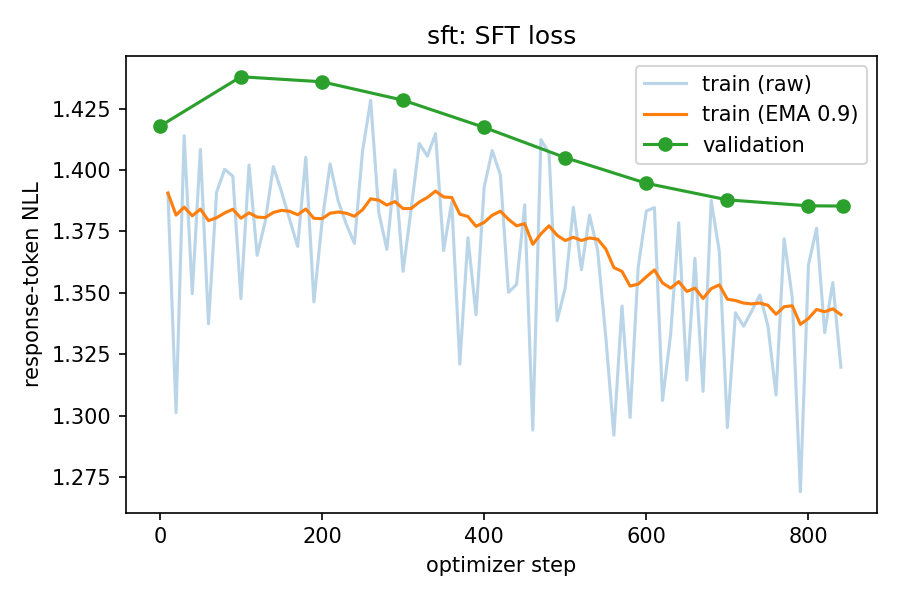

In [10]:
# =============================================================================
# Step 8a: training curves
# =============================================================================
!python scripts/plot_metrics.py --run outputs/sft --kind sft
from IPython.display import Image, display
display(Image("outputs/sft/sft_curves.png"))

In [11]:
# =============================================================================
# Step 8b: sanity-check the SFT checkpoint on 3 prompts (path, template, EOS, length)
# =============================================================================
sh("python scripts/generate.py --model_path outputs/sft/best --generator sft --limit 3 "
   "--eval_set eval_sets/alpaca_eval_300_seed42.json --output outputs/generations/_sanity_sft.json")

The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
3/3
saved 3 generations -> outputs/generations/_sanity_sft.json
PROMPT: What are the names of some famous actors that started their careers on Broadway? 
---
OUTPUT: 1. Marlon Brando
2. James Dean
3. John Wayne
4. Robert De Niro
5. Tom Hiddleston
6. Michael Fassbender
7. Leonardo DiCaprio
8. Tom Hardy
9. Scarlett Johansson
10. Bradley Cooper
PROMPT: Hi, my sister and her girlfriends want me to play kickball with them. Can you explain how the game is played, so they don't take advantage of me? 
---
OUTPUT: Sure! Here's a simple description of how kickball works:

1. The ball is thrown by one player from the c

In [12]:
# =============================================================================
# Step 9: small zip of logs/metrics/generations (checkpoints stay as folders; zipping 2 GB files doubles disk use)
# =============================================================================
!zip -q -r /kaggle/working/sft_run_outputs.zip outputs -x "*.safetensors"
!du -sh outputs/* /kaggle/working/sft_run_outputs.zip

1.3M	outputs/generations
3.8G	outputs/sft
7.9M	/kaggle/working/sft_run_outputs.zip


## Final step · Preserve the outputs  (PA2 Sec. 5.5)
1. Click **Save Version → Save & Run All (Commit)** (or, if you ran interactively, *Quick Save* keeps the current outputs).
2. After the version finishes, its `/kaggle/working` folder becomes an **Output** you can attach to the next notebook with **Add Input → Your Work → Notebooks**.